<a href="https://colab.research.google.com/github/eunicesmartinez/philippines-poverty-incidence-analysis/blob/main/notebooks/01_inspect_poverty_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:

import pandas as pd

url = "https://raw.githubusercontent.com/eunicesmartinez/philippines-poverty-spending-analysis/main/data/raw/psa_poverty_table_2a.csv"

df = pd.read_csv(
    url,
    encoding="utf-8-sig",
    skiprows=1,
    dtype=str
)

print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Rows and columns: (142, 19)

Column names:
['Geolocation', 'Annual Per Capita Poverty Threshold (in PhP) 2018', 'Annual Per Capita Poverty Threshold (in PhP) 2021', 'Annual Per Capita Poverty Threshold (in PhP) 2023', 'Poverty Incidence among Population (%) 2018', 'Poverty Incidence among Population (%) 2021', 'Poverty Incidence among Population (%) 2023', 'Coefficient of Variation 2018', 'Coefficient of Variation 2021', 'Coefficient of Variation 2023', 'Standard Error 2018', 'Standard Error 2021', 'Standard Error 2023', '95% Confidence Interval (Lower Limit) 2018', '95% Confidence Interval (Lower Limit) 2021', '95% Confidence Interval (Lower Limit) 2023', '95% Confidence Interval (Upper Limit) 2018', '95% Confidence Interval (Upper Limit) 2021', '95% Confidence Interval (Upper Limit) 2023']


,Geolocation,Annual Per Capita Poverty Threshold (in PhP) 2018,Annual Per Capita Poverty Threshold (in PhP) 2021,Annual Per Capita Poverty Threshold (in PhP) 2023,Poverty Incidence among Population (%) 2018,Poverty Incidence among Population (%) 2021,Poverty Incidence among Population (%) 2023,Coefficient of Variation 2018,Coefficient of Variation 2021,Coefficient of Variation 2023,Standard Error 2018,Standard Error 2021,Standard Error 2023,95% Confidence Interval (Lower Limit) 2018,95% Confidence Interval (Lower Limit) 2021,95% Confidence Interval (Lower Limit) 2023,95% Confidence Interval (Upper Limit) 2018,95% Confidence Interval (Upper Limit) 2021,95% Confidence Interval (Upper Limit) 2023
0,"PHILIPPINES r1, 1/, 2/, 3/",25814,28794,33296,17,18,16,1,1,1,0,0,0,16,18,15,17,19,16
1,"..National Capital Region (NCR) 1/, 2/, a/",28682,32978,37711,2,4,2,11,7,10,0,0,0,2,3,2,3,4,2
2,....1st District,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..
3,"....City of Manila a/, b/, c/",28682,32978,37711,3,2,2,30,33,27,1,1,1,1,1,1,5,3,4
4,....2nd District,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..


In [7]:

# Inspect geography names
print("First 30 geography labels:")
print(df["Geolocation"].head(30).to_string(index=False))

# Check for missing-value markers
print("\nOccurrences of '..' in each column:")
print((df == "..").sum())

print("\nOccurrences of '-' in each column:")
print((df == "-").sum())

# Check whether any rows are completely duplicated
print("\nDuplicate rows:", df.duplicated().sum())


First 30 geography labels:
                        PHILIPPINES r1, 1/, 2/, 3/
        ..National Capital Region (NCR) 1/, 2/, a/
                                  ....1st District
                     ....City of Manila a/, b/, c/
                                  ....2nd District
                ....City of Mandaluyong a/, b/, c/
               ....City of Marikina 2/, a/, b/, c/
                      ....City of Pasig a/, b/, c/
                    ....Quezon City 2/, a/, b/, c/
                    ....City of San Juan *, **, a/
                                  ....3rd District
               ....City of Caloocan 2/, a/, b/, c/
            ....City of Malabon 1/, 2/, a/, b/, c/
                    ....City of Navotas a/, b/, c/
             ....City of Valenzuela 1/, a/, b/, c/
                                  ....4th District
          ....City of Las Pi�as 1/, 2/, a/, b/, c/
                 ....City of Makati 1/, a/, b/, c/
     ....City of Muntinlupa 1/, 2/, 3/, a/, b/, c/
    

In [8]:

# Identify rows where every statistical value is '..'
stat_cols = df.columns.drop("Geolocation")

heading_mask = df[stat_cols].eq("..").all(axis=1)

print("Rows with no statistical values:", heading_mask.sum())
print("\nThese geography labels appear to be headings:")
print(df.loc[heading_mask, "Geolocation"].to_string(index=False))

# Inspect rows containing '-' markers
hyphen_mask = df.eq("-").any(axis=1)

print("\nRows containing '-' markers:")
display(df.loc[hyphen_mask])

# Confirm total rows
print("\nTotal rows:", len(df))


Rows with no statistical values: 4

These geography labels appear to be headings:
....1st District
....2nd District
....3rd District
....4th District

Rows containing '-' markers:


,Geolocation,Annual Per Capita Poverty Threshold (in PhP) 2018,Annual Per Capita Poverty Threshold (in PhP) 2021,Annual Per Capita Poverty Threshold (in PhP) 2023,Poverty Incidence among Population (%) 2018,Poverty Incidence among Population (%) 2021,Poverty Incidence among Population (%) 2023,Coefficient of Variation 2018,Coefficient of Variation 2021,Coefficient of Variation 2023,Standard Error 2018,Standard Error 2021,Standard Error 2023,95% Confidence Interval (Lower Limit) 2018,95% Confidence Interval (Lower Limit) 2021,95% Confidence Interval (Lower Limit) 2023,95% Confidence Interval (Upper Limit) 2018,95% Confidence Interval (Upper Limit) 2021,95% Confidence Interval (Upper Limit) 2023
9,"....City of San Juan *, **, a/",28682,32978,37711,1,-,-,74,-,-,1,-,-,0,-,-,2,-,-



Total rows: 142


In [9]:

# Create a working copy; leave the original df unchanged
poverty = df.copy()

# Remove footnote annotations and leading dots from geography labels
poverty["Geolocation"] = (
    poverty["Geolocation"]
    .str.replace(r"^\.+", "", regex=True)
    .str.replace(r"\s+(?:r\d+|(?:\d+|[a-z]|\*)+\/?)(?:,.*)?$", "", regex=True)
    .str.strip()
)

# Remove district-heading rows with no statistical values
stat_cols = poverty.columns.drop("Geolocation")
heading_mask = poverty[stat_cols].eq("..").all(axis=1)
poverty = poverty.loc[~heading_mask].copy()

# Convert special markers to missing values
poverty = poverty.replace({"..": pd.NA, "-": pd.NA})

print("Original rows:", len(df))
print("Rows after removing headings:", len(poverty))
print("\nSample geography labels:")
print(poverty["Geolocation"].head(25).to_string(index=False))

print("\nRemaining missing values by column:")
print(poverty.isna().sum())


Original rows: 142
Rows after removing headings: 138

Sample geography labels:
                           PHILIPPINES
         National Capital Region (NCR)
                        City of Manila
                   City of Mandaluyong
                      City of Marikina
                         City of Pasig
                           Quezon City
                      City of San Juan
                      City of Caloocan
                       City of Malabon
                       City of Navotas
                    City of Valenzuela
                     City of Las Pi�as
                        City of Makati
                    City of Muntinlupa
                     City of Para�aque
                            Pasay City
                               Pateros
                        City of Taguig
Cordillera Administrative Region (CAR)
                                  Abra
                                Apayao
      Benguet (w/o the City of Baguio)
                        

In [10]:

poverty_cols = [
    "Poverty Incidence among Population (%) 2018",
    "Poverty Incidence among Population (%) 2021",
    "Poverty Incidence among Population (%) 2023"
]

# Find locations missing at least one poverty estimate
missing_mask = poverty[poverty_cols].isna().any(axis=1)

print("Locations with missing poverty estimates:")
display(poverty.loc[missing_mask, ["Geolocation"] + poverty_cols])

# Check for remaining geography-name encoding issues
print("\nGeography names containing the replacement character:")
print(
    poverty.loc[
        poverty["Geolocation"].str.contains("�", na=False),
        "Geolocation"
    ].to_list()
)


Locations with missing poverty estimates:


,Geolocation,Poverty Incidence among Population (%) 2018,Poverty Incidence among Population (%) 2021,Poverty Incidence among Population (%) 2023
9,City of San Juan,1,<NA>,<NA>
137,Maguindanao del Norte,<NA>,<NA>,40
138,Maguindanao del Sur,<NA>,<NA>,43



Geography names containing the replacement character:
['City of Las Pi�as', 'City of Para�aque']


In [11]:

# Correct the two corrupted names in the working copy
poverty["Geolocation"] = poverty["Geolocation"].replace({
    "City of Las Pi�as": "City of Las Piñas",
    "City of Para�aque": "City of Parañaque"
})

# Verify the corrections
print(
    poverty.loc[
        poverty["Geolocation"].str.contains(
            "Las Piñas|Parañaque", case=False, regex=True, na=False
        ),
        "Geolocation"
    ].to_list()
)


['City of Las Piñas', 'City of Parañaque']


In [12]:

# Select the poverty-incidence columns
incidence_cols = [
    "Poverty Incidence among Population (%) 2018",
    "Poverty Incidence among Population (%) 2021",
    "Poverty Incidence among Population (%) 2023"
]

# Reshape from wide format to long format
poverty_long = poverty[["Geolocation"] + incidence_cols].melt(
    id_vars="Geolocation",
    value_vars=incidence_cols,
    var_name="Measure",
    value_name="Poverty_Incidence_Pct"
)

# Extract the year from each column name
poverty_long["Year"] = (
    poverty_long["Measure"].str.extract(r"(\d{4})").astype(int)
)

# Remove the original measure label; the column name already tells us the measure
poverty_long = poverty_long.drop(columns="Measure")

# Convert percentages to numeric values, preserving missing estimates
poverty_long["Poverty_Incidence_Pct"] = pd.to_numeric(
    poverty_long["Poverty_Incidence_Pct"],
    errors="coerce"
)

# Arrange columns and rows
poverty_long = poverty_long[
    ["Geolocation", "Year", "Poverty_Incidence_Pct"]
].sort_values(["Geolocation", "Year"]).reset_index(drop=True)

print("Rows and columns:", poverty_long.shape)
display(poverty_long.head(10))


Rows and columns: (414, 3)


,Geolocation,Year,Poverty_Incidence_Pct
0,Abra,2018,19.0
1,Abra,2021,22.0
2,Abra,2023,14.0
3,Agusan del Norte (w/o the City of Butuan),2018,28.0
4,Agusan del Norte (w/o the City of Butuan),2021,32.0
5,Agusan del Norte (w/o the City of Butuan),2023,23.0
6,Agusan del Sur,2018,38.0
7,Agusan del Sur,2021,41.0
8,Agusan del Sur,2023,32.0
9,Aklan,2018,12.0


In [13]:

# 1. Check that every location-year combination is unique
print("Duplicate location-year pairs:",
      poverty_long.duplicated(["Geolocation", "Year"]).sum())

# 2. Check the years included
print("\nYears:", sorted(poverty_long["Year"].unique()))

# 3. Summarize missing values
print("\nMissing values:")
print(poverty_long.isna().sum())

# 4. Check the range of poverty incidence values
print("\nPoverty incidence summary:")
print(poverty_long["Poverty_Incidence_Pct"].describe())

# 5. Inspect the highest poverty-incidence estimates
print("\nHighest poverty-incidence estimates:")
display(
    poverty_long
    .sort_values("Poverty_Incidence_Pct", ascending=False)
    .head(10)
)


Duplicate location-year pairs: 0

Years: [np.int64(2018), np.int64(2021), np.int64(2023)]

Missing values:
Geolocation              0
Year                     0
Poverty_Incidence_Pct    6
dtype: int64

Poverty incidence summary:
count    408.000000
mean      18.073529
std       13.408329
min        0.000000
25%        7.000000
50%       16.000000
75%       27.000000
max       83.000000
Name: Poverty_Incidence_Pct, dtype: float64

Highest poverty-incidence estimates:


,Geolocation,Year,Poverty_Incidence_Pct
387,Sulu,2018,83.0
27,Basilan,2018,74.0
234,Lanao del Sur,2018,71.0
24,Bangsamoro Autonomous Region in Muslim Mindana...,2018,60.0
28,Basilan,2021,54.0
388,Sulu,2021,53.0
219,Isabela City,2018,51.0
409,Zamboanga del Norte,2021,51.0
198,Eastern Samar,2018,50.0
243,Maguindanao,2018,49.0


In [14]:

# Check whether any poverty-incidence estimates are zero
zero_mask = poverty_long["Poverty_Incidence_Pct"].eq(0)

print("Number of zero estimates:", zero_mask.sum())
display(
    poverty_long.loc[zero_mask]
    .sort_values(["Geolocation", "Year"])
)

# List all missing estimates
print("\nMissing poverty-incidence estimates:")
display(
    poverty_long.loc[
        poverty_long["Poverty_Incidence_Pct"].isna()
    ].sort_values(["Geolocation", "Year"])
)


Number of zero estimates: 2


,Geolocation,Year,Poverty_Incidence_Pct
120,City of Makati,2018,0.0
140,City of Muntinlupa,2023,0.0



Missing poverty-incidence estimates:


,Geolocation,Year,Poverty_Incidence_Pct
157,City of San Juan,2021,NaN
158,City of San Juan,2023,NaN
246,Maguindanao del Norte,2018,NaN
247,Maguindanao del Norte,2021,NaN
249,Maguindanao del Sur,2018,NaN
250,Maguindanao del Sur,2021,NaN


In [15]:

print("Data types:")
print(poverty_long.dtypes)

print("\nValues outside the expected percentage range (0–100):")
display(
    poverty_long.loc[
        poverty_long["Poverty_Incidence_Pct"].notna()
        & ~poverty_long["Poverty_Incidence_Pct"].between(0, 100)
    ]
)


Data types:
Geolocation               object
Year                       int64
Poverty_Incidence_Pct    float64
dtype: object

Values outside the expected percentage range (0–100):


,Geolocation,Year,Poverty_Incidence_Pct


In [16]:

from pathlib import Path

# Create the output directory
Path("data/processed").mkdir(parents=True, exist_ok=True)

# Export the cleaned poverty-incidence dataset
output_path = "poverty_incidence_clean.csv"

poverty_long.to_csv(output_path, index=False, na_rep="")

print("Exported:", output_path)
print("Rows:", len(poverty_long))
print("Columns:", poverty_long.columns.tolist())


Exported: poverty_incidence_clean.csv
Rows: 414
Columns: ['Geolocation', 'Year', 'Poverty_Incidence_Pct']


In [17]:

from google.colab import files

files.download("poverty_incidence_clean.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
from google.colab import files

uploaded = files.upload()

Saving poverty_incidence_clean (1).csv to poverty_incidence_clean (1) (1).csv


,Year,Poverty_Incidence_Pct
294,2018,17.0
295,2021,18.0
296,2023,16.0


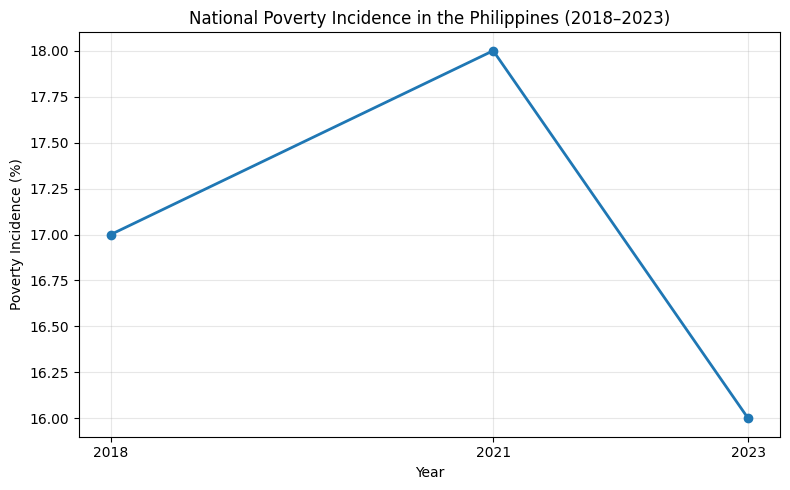

In [24]:
import matplotlib.pyplot as plt

# Select the national poverty incidence estimates
national = df[df["Geolocation"] == "PHILIPPINES"].copy()

# Sort the years in chronological order
national = national.sort_values("Year")

# Display the data we'll be plotting
display(national[["Year", "Poverty_Incidence_Pct"]])

# Create the line chart
plt.figure(figsize=(8, 5))

plt.plot(
    national["Year"],
    national["Poverty_Incidence_Pct"],
    marker="o",
    linewidth=2
)

plt.title("National Poverty Incidence in the Philippines (2018–2023)")
plt.xlabel("Year")
plt.ylabel("Poverty Incidence (%)")
plt.xticks([2018, 2021, 2023])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

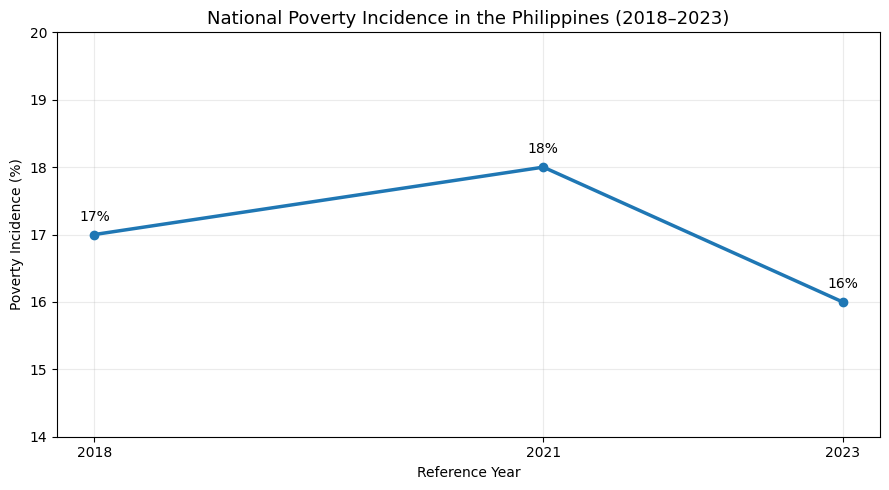

In [25]:
# Create a polished chart
plt.figure(figsize=(9, 5))

plt.plot(
    national["Year"],
    national["Poverty_Incidence_Pct"],
    marker="o",
    linewidth=2.5
)

# Label each data point
for year, value in zip(
    national["Year"],
    national["Poverty_Incidence_Pct"]
):
    plt.annotate(
        f"{value:.0f}%",
        (year, value),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.title(
    "National Poverty Incidence in the Philippines (2018–2023)",
    fontsize=13
)
plt.xlabel("Reference Year")
plt.ylabel("Poverty Incidence (%)")
plt.xticks([2018, 2021, 2023])
plt.ylim(14, 20)
plt.grid(True, alpha=0.25)
plt.tight_layout()

# Save the chart as a high-resolution image
plt.savefig(
    "national_poverty_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
from google.colab import files

files.download("national_poverty_trend.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

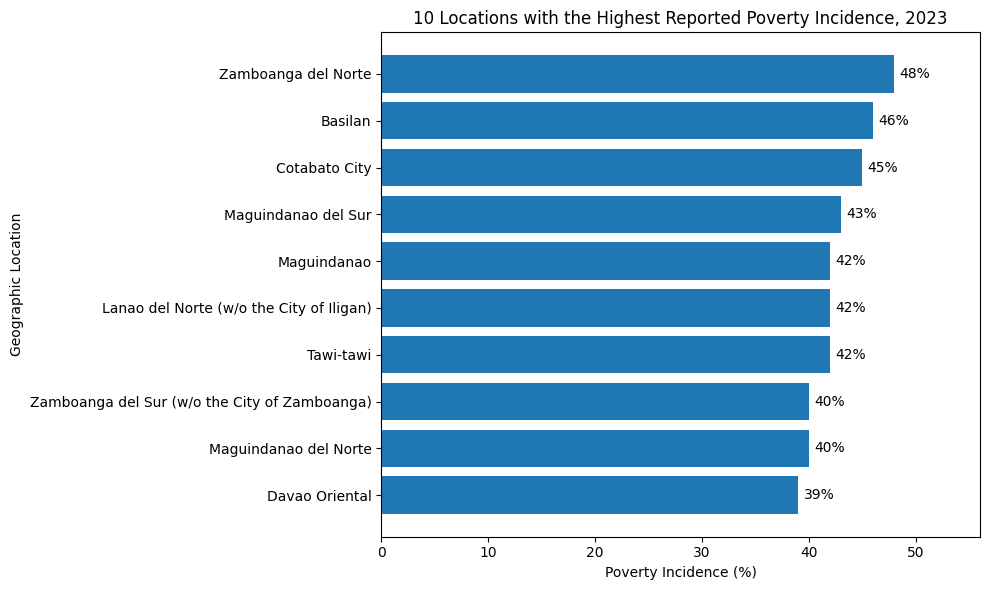

In [27]:
# Select 2023 records with available poverty incidence estimates
poverty_2023 = df[
    (df["Year"] == 2023) &
    (df["Poverty_Incidence_Pct"].notna())
].copy()

# Select the 10 locations with the highest reported incidence
top_10 = poverty_2023.nlargest(10, "Poverty_Incidence_Pct")

# Reverse the order so the highest value appears at the top
top_10 = top_10.sort_values("Poverty_Incidence_Pct", ascending=True)

# Create the horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10["Geolocation"],
    top_10["Poverty_Incidence_Pct"]
)

# Add labels to the bars
for location, value in zip(
    top_10["Geolocation"],
    top_10["Poverty_Incidence_Pct"]
):
    plt.text(value + 0.5, location, f"{value:.0f}%", va="center")

plt.title("10 Locations with the Highest Reported Poverty Incidence, 2023")
plt.xlabel("Poverty Incidence (%)")
plt.ylabel("Geographic Location")
plt.xlim(0, top_10["Poverty_Incidence_Pct"].max() + 8)
plt.tight_layout()

# Save the chart
plt.savefig("top_10_poverty_incidence_2023.png", dpi=300, bbox_inches="tight")

plt.show()

In [28]:
from google.colab import files

files.download("top_10_poverty_incidence_2023.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

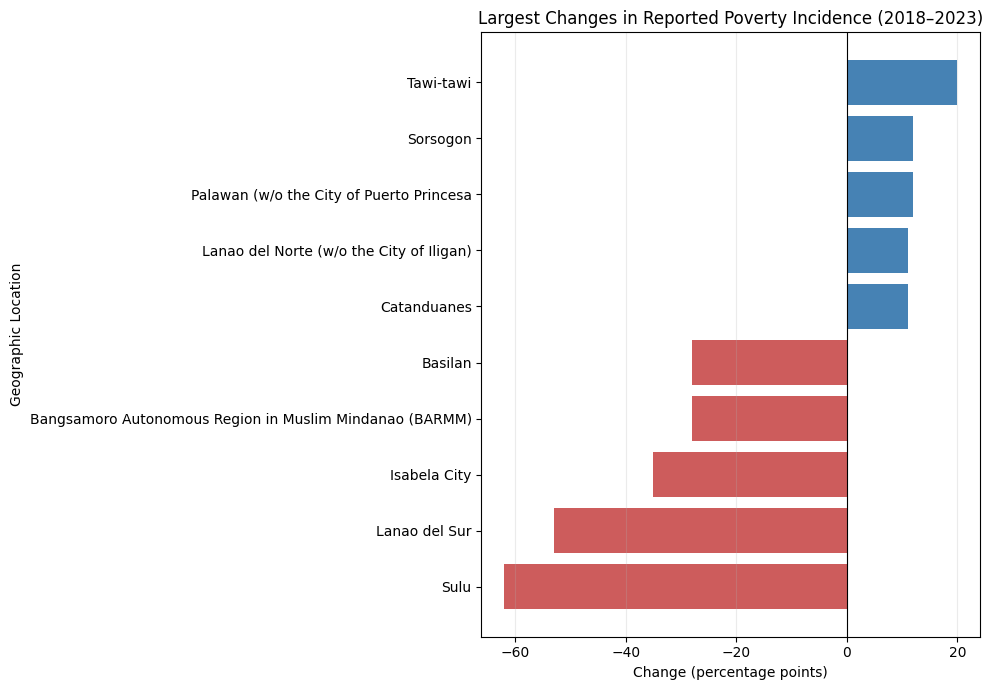

In [29]:
# Keep only the 2018 and 2023 records
comparison = df[df["Year"].isin([2018, 2023])].copy()

# Reshape the data so each location has separate 2018 and 2023 columns
comparison_wide = comparison.pivot(
    index="Geolocation",
    columns="Year",
    values="Poverty_Incidence_Pct"
)

# Keep locations with reported estimates in both years
comparison_wide = comparison_wide.dropna(subset=[2018, 2023]).copy()

# Calculate change in percentage points
comparison_wide["Change_Points"] = (
    comparison_wide[2023] - comparison_wide[2018]
)

# Select the 5 largest increases and 5 largest decreases
largest_increases = comparison_wide.nlargest(5, "Change_Points")
largest_decreases = comparison_wide.nsmallest(5, "Change_Points")

selected = pd.concat([largest_decreases, largest_increases])

# Sort for a diverging horizontal bar chart
selected = selected.sort_values("Change_Points")

# Create the chart
plt.figure(figsize=(10, 7))

bar_colors = [
    "indianred" if value < 0 else "steelblue"
    for value in selected["Change_Points"]
]

plt.barh(
    selected.index,
    selected["Change_Points"],
    color=bar_colors
)

# Add a zero reference line
plt.axvline(0, color="black", linewidth=0.8)

plt.title("Largest Changes in Reported Poverty Incidence (2018–2023)")
plt.xlabel("Change (percentage points)")
plt.ylabel("Geographic Location")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

# Save the chart
plt.savefig(
    "poverty_incidence_change_2018_2023.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
from google.colab import files

files.download("poverty_incidence_change_2018_2023.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
from google.colab import files
uploaded = files.upload()


Saving psa_poverty_table_2a.csv to psa_poverty_table_2a.csv


In [34]:
raw_df = pd.read_csv(
    "psa_poverty_table_2a.csv",
    skiprows=1,
    na_values=[".."]
)

print("Dataset shape:", raw_df.shape)
print("\nColumn names:")
print(raw_df.columns.tolist())

raw_df.head()


Dataset shape: (142, 19)

Column names:
['Geolocation', 'Annual Per Capita Poverty Threshold (in PhP) 2018', 'Annual Per Capita Poverty Threshold (in PhP) 2021', 'Annual Per Capita Poverty Threshold (in PhP) 2023', 'Poverty Incidence among Population (%) 2018', 'Poverty Incidence among Population (%) 2021', 'Poverty Incidence among Population (%) 2023', 'Coefficient of Variation 2018', 'Coefficient of Variation 2021', 'Coefficient of Variation 2023', 'Standard Error 2018', 'Standard Error 2021', 'Standard Error 2023', '95% Confidence Interval (Lower Limit) 2018', '95% Confidence Interval (Lower Limit) 2021', '95% Confidence Interval (Lower Limit) 2023', '95% Confidence Interval (Upper Limit) 2018', '95% Confidence Interval (Upper Limit) 2021', '95% Confidence Interval (Upper Limit) 2023']


,Geolocation,Annual Per Capita Poverty Threshold (in PhP) 2018,Annual Per Capita Poverty Threshold (in PhP) 2021,Annual Per Capita Poverty Threshold (in PhP) 2023,Poverty Incidence among Population (%) 2018,Poverty Incidence among Population (%) 2021,Poverty Incidence among Population (%) 2023,Coefficient of Variation 2018,Coefficient of Variation 2021,Coefficient of Variation 2023,Standard Error 2018,Standard Error 2021,Standard Error 2023,95% Confidence Interval (Lower Limit) 2018,95% Confidence Interval (Lower Limit) 2021,95% Confidence Interval (Lower Limit) 2023,95% Confidence Interval (Upper Limit) 2018,95% Confidence Interval (Upper Limit) 2021,95% Confidence Interval (Upper Limit) 2023
0,"PHILIPPINES r1, 1/, 2/, 3/",25814.0,28794.0,33296.0,17.0,18,16,1.0,1,1,0.0,0,0,16.0,18,15,17.0,19,16
1,"..National Capital Region (NCR) 1/, 2/, a/",28682.0,32978.0,37711.0,2.0,4,2,11.0,7,10,0.0,0,0,2.0,3,2,3.0,4,2
2,....1st District,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"....City of Manila a/, b/, c/",28682.0,32978.0,37711.0,3.0,2,2,30.0,33,27,1.0,1,1,1.0,1,1,5.0,3,4
4,....2nd District,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
raw_df[["Geolocation"]].head(25)


,Geolocation
0,"PHILIPPINES r1, 1/, 2/, 3/"
1,"..National Capital Region (NCR) 1/, 2/, a/"
2,....1st District
3,"....City of Manila a/, b/, c/"
4,....2nd District
5,"....City of Mandaluyong a/, b/, c/"
6,"....City of Marikina 2/, a/, b/, c/"
7,"....City of Pasig a/, b/, c/"
8,"....Quezon City 2/, a/, b/, c/"
9,"....City of San Juan *, **, a/"


In [36]:
incidence_cols = [
    "Poverty Incidence among Population (%) 2018",
    "Poverty Incidence among Population (%) 2021",
    "Poverty Incidence among Population (%) 2023"
]

has_estimate = raw_df[incidence_cols].notna().any(axis=1)

print("Total raw rows:", len(raw_df))
print("Rows with at least one poverty estimate:", has_estimate.sum())
print("Rows with no poverty estimates:", (~has_estimate).sum())


Total raw rows: 142
Rows with at least one poverty estimate: 138
Rows with no poverty estimates: 4


In [37]:
raw_df.loc[~has_estimate, ["Geolocation"]]


,Geolocation
2,....1st District
4,....2nd District
10,....3rd District
15,....4th District


In [38]:

# Keep only rows with at least one poverty incidence estimate
data = raw_df.loc[has_estimate].copy()

# Remove footnote markers and indentation from geographic labels
data["Geolocation"] = (
    data["Geolocation"]
    .str.replace(r"^\.+", "", regex=True)
    .str.replace(r"\s+(?:r\d+|[123]/|[a-z]/|\*+)(?:,.*)?$", "", regex=True)
    .str.strip()
)

# Reshape the poverty incidence values into one row per location and year
incidence_cols = {
    2018: "Poverty Incidence among Population (%) 2018",
    2021: "Poverty Incidence among Population (%) 2021",
    2023: "Poverty Incidence among Population (%) 2023",
}

# Rename precision columns into a consistent format
precision_cols = {
    2018: {
        "cv": "Coefficient of Variation 2018",
        "se": "Standard Error 2018",
        "ci_lower": "95% Confidence Interval (Lower Limit) 2018",
        "ci_upper": "95% Confidence Interval (Upper Limit) 2018",
        "threshold": "Annual Per Capita Poverty Threshold (in PhP) 2018",
    },
    2021: {
        "cv": "Coefficient of Variation 2021",
        "se": "Standard Error 2021",
        "ci_lower": "95% Confidence Interval (Lower Limit) 2021",
        "ci_upper": "95% Confidence Interval (Upper Limit) 2021",
        "threshold": "Annual Per Capita Poverty Threshold (in PhP) 2021",
    },
    2023: {
        "cv": "Coefficient of Variation 2023",
        "se": "Standard Error 2023",
        "ci_lower": "95% Confidence Interval (Lower Limit) 2023",
        "ci_upper": "95% Confidence Interval (Upper Limit) 2023",
        "threshold": "Annual Per Capita Poverty Threshold (in PhP) 2023",
    },
}

records = []

for _, row in data.iterrows():
    for year in [2018, 2021, 2023]:
        records.append({
            "Geolocation": row["Geolocation"],
            "Year": year,
            "Poverty_Incidence_Pct": row[incidence_cols[year]],
            "Poverty_Threshold_PHP": row[precision_cols[year]["threshold"]],
            "Coefficient_of_Variation_Pct": row[precision_cols[year]["cv"]],
            "Standard_Error_Pct_Points": row[precision_cols[year]["se"]],
            "CI_Lower_Pct": row[precision_cols[year]["ci_lower"]],
            "CI_Upper_Pct": row[precision_cols[year]["ci_upper"]],
        })

enhanced_df = pd.DataFrame(records)

print("Enhanced dataset shape:", enhanced_df.shape)
print("\nColumns:")
print(enhanced_df.columns.tolist())

enhanced_df.head()


Enhanced dataset shape: (414, 8)

Columns:
['Geolocation', 'Year', 'Poverty_Incidence_Pct', 'Poverty_Threshold_PHP', 'Coefficient_of_Variation_Pct', 'Standard_Error_Pct_Points', 'CI_Lower_Pct', 'CI_Upper_Pct']


,Geolocation,Year,Poverty_Incidence_Pct,Poverty_Threshold_PHP,Coefficient_of_Variation_Pct,Standard_Error_Pct_Points,CI_Lower_Pct,CI_Upper_Pct
0,PHILIPPINES,2018,17.0,25814.0,1.0,0.0,16.0,17.0
1,PHILIPPINES,2021,18,28794.0,1,0,18,19
2,PHILIPPINES,2023,16,33296.0,1,0,15,16
3,National Capital Region (NCR),2018,2.0,28682.0,11.0,0.0,2.0,3.0
4,National Capital Region (NCR),2021,4,32978.0,7,0,3,4


In [39]:
print("Unique geographic labels:", enhanced_df["Geolocation"].nunique())
print("Rows per year:")
print(enhanced_df.groupby("Year").size())

print("\nMissing values by column:")
print(enhanced_df.isna().sum())

print("\nSulu precision values:")
print(
    enhanced_df.loc[
        enhanced_df["Geolocation"].str.contains("Sulu", case=False, na=False),
        [
            "Geolocation",
            "Year",
            "Poverty_Incidence_Pct",
            "Coefficient_of_Variation_Pct",
            "Standard_Error_Pct_Points",
            "CI_Lower_Pct",
            "CI_Upper_Pct",
        ],
    ].to_string(index=False)
)


Unique geographic labels: 138
Rows per year:
Year
2018    138
2021    138
2023    138
dtype: int64

Missing values by column:
Geolocation                     0
Year                            0
Poverty_Incidence_Pct           4
Poverty_Threshold_PHP           4
Coefficient_of_Variation_Pct    4
Standard_Error_Pct_Points       4
CI_Lower_Pct                    4
CI_Upper_Pct                    4
dtype: int64

Sulu precision values:
Geolocation  Year Poverty_Incidence_Pct Coefficient_of_Variation_Pct Standard_Error_Pct_Points CI_Lower_Pct CI_Upper_Pct
       Sulu  2018                  83.0                          2.0                       2.0         79.0         86.0
       Sulu  2021                    53                            5                         3           48           58
       Sulu  2023                    21                           11                         2           16           25


In [40]:
output_file = "poverty_incidence_with_precision.csv"

enhanced_df.to_csv(output_file, index=False)

print(f"Saved {output_file}")


Saved poverty_incidence_with_precision.csv


In [41]:
from google.colab import files
files.download("poverty_incidence_with_precision.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>